# Logistic regression in 2D: gradient descent

This notebook creates two synthetic 2D datasets, one **linearly separable** and one **non-separable**, and trains a logistic regression classifier on each **with vanilla gradient descent** on the **logistic loss**. There is no bias term: the classes are symmetric with respect to the origin, and we only look for separators passing through $0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Data generator

In [2]:
def make_gaussian_classes(n_per_class=200, mean=2.0, cov=np.eye(2)):
    # Class +1 is centred at (mean, mean), class -1 at (-mean, -mean): symmetric with respect to 0
    mean_pos = np.array([mean, mean])
    X_pos = np.random.multivariate_normal(mean_pos, cov, size=n_per_class)
    X_neg = np.random.multivariate_normal(-mean_pos, cov, size=n_per_class)
    X = np.vstack([X_pos, X_neg])
    y = np.hstack([np.ones(n_per_class), -np.ones(n_per_class)])
    return X, y

## Create datasets

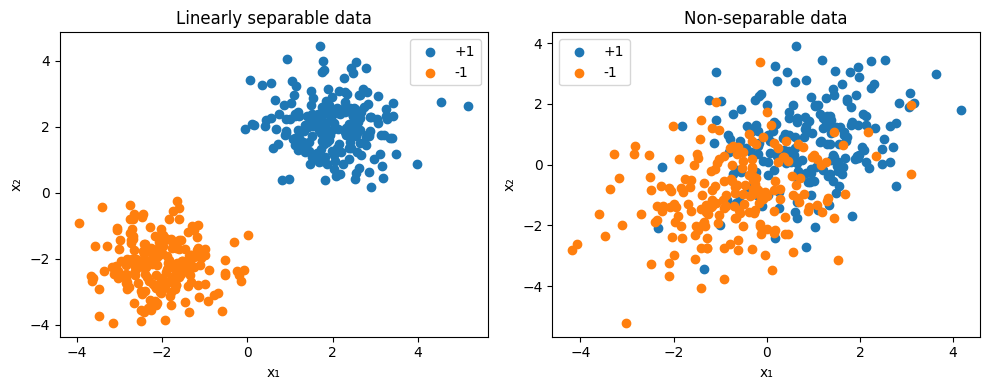

In [3]:
np.random.seed(2)

# Generate datasets
X_sep, y_sep = make_gaussian_classes(n_per_class=200, mean=2.0, cov=0.6 * np.eye(2))
X_nonsep, y_nonsep = make_gaussian_classes(n_per_class=200, mean=0.8, cov=np.array([[1.6, 0.4], [0.4, 1.6]]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Plot linearly separable
axes[0].scatter(X_sep[y_sep == 1, 0], X_sep[y_sep == 1, 1], label="+1")
axes[0].scatter(X_sep[y_sep == -1, 0], X_sep[y_sep == -1, 1], label="-1")
axes[0].set_title("Linearly separable data")
axes[0].set_xlabel("x₁")
axes[0].set_ylabel("x₂")
axes[0].legend()

# Plot non-separable
axes[1].scatter(X_nonsep[y_nonsep == 1, 0], X_nonsep[y_nonsep == 1, 1], label="+1")
axes[1].scatter(X_nonsep[y_nonsep == -1, 0], X_nonsep[y_nonsep == -1, 1], label="-1")
axes[1].set_title("Non-separable data")
axes[1].set_xlabel("x₁")
axes[1].set_ylabel("x₂")
axes[1].legend()

plt.tight_layout()
plt.show()

## Logistic loss and gradient

With labels $y_i \in \{-1, +1\}$, inputs $x_i \in \mathbb{R}^2$ and parameter $w = (w_0, w_1) \in \mathbb{R}^2$, the logistic loss is

$$
L(w) = \frac{1}{n} \sum_{i=1}^n \log\left(1 + e^{-y_i \langle w, x_i \rangle}\right) + \frac{\lambda}{2} \|w\|^2,
$$

where $\lambda$ is the argument `reg` (it is $0$ until the last part).

**Hint.** With $\sigma(t) = 1 / (1 + e^{-t})$, the derivative of $t \mapsto \log(1 + e^{-t})$ is $-\sigma(-t)$. To compute $\sigma(-t)$ without overflow, use `np.exp(-np.logaddexp(0.0, t))`.

In [ ]:
def logistic_loss_and_grad(w, X, y, reg=0.0):
    # X shape: (n, d)

    # TODO compute logistic loss and gradient at point w
    # use np.logaddexp instead of log(1 + exp(-yz)) for more stability
    ...
    ...
    ...
    return loss, grad_w

## Gradient descent optimiser

In [5]:
def train_log_gd(X, y, lr=0.5, steps=1500, reg=0.0):
    w = np.zeros(X.shape[1])
    ws, losses = [], []
    for t in range(steps):
        loss, gw = logistic_loss_and_grad(w, X, y, reg)
        losses.append(loss)
        ws.append(w.copy())
        w -= lr * gw
    return np.array(ws), np.array(losses)

## Plot helpers

In [6]:
def plot_training_loss(losses, title="Loss vs iterations", loglog=True):
    iters = np.arange(1, len(losses) + 1)
    plt.figure(figsize=(5, 4))
    if loglog:
        plt.loglog(iters, losses)
    else:
        plt.plot(iters, losses)
    plt.xlabel("Iteration")
    plt.ylabel("Training logistic loss")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def plot_data_with_separator(Xs, y, w, title, w_max_margin=None):
    # Xs is the 2D feature matrix
    # If w_max_margin is given, the max-margin separator is also drawn
    plt.figure()
    X_pos = Xs[y == 1]
    X_neg = Xs[y == -1]
    plt.scatter(X_pos[:,0], X_pos[:,1], label="+1")
    plt.scatter(X_neg[:,0], X_neg[:,1], label="-1")
    # Decision boundary: w0*x + w1*y = 0  => y = -w0*x/w1
    x_min, x_max = Xs[:,0].min() - 0.5, Xs[:,0].max() + 0.5
    xs = np.linspace(x_min, x_max, 200)
    w0, w1 = w[0], w[1]
    if abs(w1) > 1e-12:
        ys = -w0 * xs / w1
        plt.plot(xs, ys, label="Separating hyperplane")
    else:
        plt.axvline(x=0, label="Separating hyperplane")
    if w_max_margin is not None:
        m0, m1 = w_max_margin
        plt.plot(xs, -m0 * xs / m1, 'k--', label="Max-margin separator")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

def plot_loss_surface(w_traj, X, y, reg=0.0, direction=None, margin_set=False, n_levels=20, title="Logistic loss surface and trajectory"):
    w_traj = np.asarray(w_traj)

    # Grid for (w0, w1)
    w0s = np.linspace(w_traj[:, 0].min() - 1, w_traj[:, 0].max() + 1, 120)
    w1s = np.linspace(w_traj[:, 1].min() - 1, w_traj[:, 1].max() + 1, 120)
    W0, W1 = np.meshgrid(w0s, w1s)

    def loss_at(w0, w1, X, y):
        w = np.array([w0, w1])
        z = X @ w
        yz = y * z
        data = np.logaddexp(0.0, -yz).mean()
        return data + 0.5 * reg * (w0**2 + w1**2)

    # Compute loss grid
    Z = np.zeros_like(W0)
    for i in range(W0.shape[0]):
        for j in range(W0.shape[1]):
            Z[i, j] = loss_at(W0[i, j], W1[i, j], X, y)

    # Plot
    fig, ax = plt.subplots(figsize=(5, 4))
    levels = np.quantile(Z, np.linspace(0, 1, n_levels + 2)[1:-1])   # more level lines where the loss is small
    cs = ax.contour(W0, W1, Z, levels=levels)
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.2g")
    ax.plot(w_traj[:, 0], w_traj[:, 1], '-o', ms=2, lw=1, label='trajectory')
    ax.scatter(w_traj[0, 0], w_traj[0, 1], color='red', label='start', zorder=3)
    ax.scatter(w_traj[-1, 0], w_traj[-1, 1], color='green', label='end', zorder=3)
    if direction is not None:
        # half-line from the origin in the given direction
        u = direction / np.linalg.norm(direction)
        c = 2 * (np.abs(w0s).max() + np.abs(w1s).max())
        ax.plot([0, c * u[0]], [0, c * u[1]], 'k--', lw=1, label='max-margin direction')
        ax.set_xlim(w0s[0], w0s[-1])
        ax.set_ylim(w1s[0], w1s[-1])
    if margin_set:
        # set of w such that min_i y_i <w, x_i> = 1
        W = np.stack([W0.ravel(), W1.ravel()])
        M = (y[:, None] * (X @ W)).min(axis=0).reshape(W0.shape)
        ax.contour(W0, W1, M, levels=[1.0], colors='red', linewidths=1.5)
        ax.plot([], [], color='red', lw=1.5, label='min_i y_i <w, x_i> = 1')
    ax.set_xlabel('w₀')
    ax.set_ylabel('w₁')
    ax.legend(fontsize=8)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## Experiment 1: linearly separable data

In [7]:
# Run gradient descent and keep all iterates
ws_sep, losses_sep = train_log_gd(X_sep, y_sep, steps=1500)

# Extract final parameters
w_sep_final = ws_sep[-1]

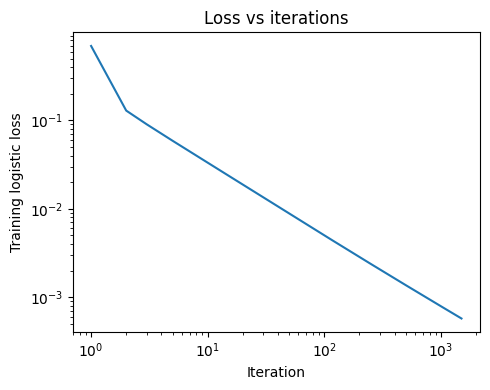

In [8]:
plot_training_loss(losses_sep, loglog = True)

**Question.** At what rate does the loss go to $0$? How can you read this rate on the log-log plot above?

Since $\|w_t\| \to \infty$, we look at the direction $w_t / \|w_t\|$. It converges to the direction of the $\ell_2$ max-margin separator

$$
\hat w = \arg\min_{w} \|w\|_2 \quad \text{such that} \quad y_i \langle w, x_i \rangle \geq 1 \text{ for all } i,
$$

which can be computed numerically (it is the hard-margin SVM).

In [9]:
def max_margin(X, y, steps=20000):
    # Computes the max-margin solution w_hat (no need to read the details)
    Z = y[:, None] * X
    lr = 1.0 / np.linalg.norm(Z, 2) ** 2
    alpha = np.zeros(Z.shape[0])
    beta, t = alpha.copy(), 1.0
    for _ in range(steps):
        alpha_new = np.maximum(0.0, beta + lr * (1.0 - Z @ (Z.T @ beta)))
        t_new = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
        beta = alpha_new + (t - 1) / t_new * (alpha_new - alpha)
        alpha, t = alpha_new, t_new
    return Z.T @ alpha

w_mm = max_margin(X_sep, y_sep)
print("smallest margin min_i y_i <w_mm, x_i> =", (y_sep * (X_sep @ w_mm)).min())   # 1 if the data is separable through 0

smallest margin min_i y_i <w_mm, x_i> = 0.999976816207209


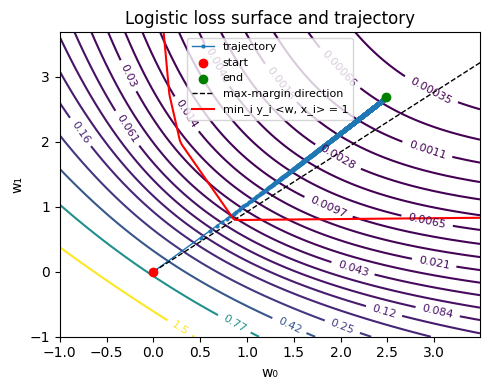

In [10]:
plot_loss_surface(ws_sep, X_sep, y_sep, direction=w_mm, margin_set=True)

The convergence in direction is very slow for gradient descent (the angle decreases like $1/\log t$). With normalised gradient descent, $w_{t+1} = w_t - \frac{\eta}{L(w_t)} \nabla L(w_t)$, it is much faster:

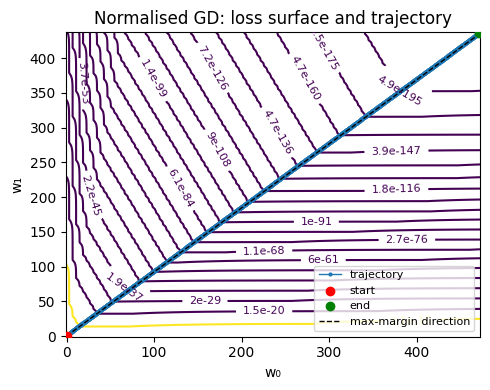

In [11]:
w = np.zeros(2)
ws_ngd = [w.copy()]
for t in range(1500):
    loss, gw = logistic_loss_and_grad(w, X_sep, y_sep)
    w -= 0.5 * gw / loss
    ws_ngd.append(w.copy())
ws_ngd = np.array(ws_ngd)

plot_loss_surface(ws_ngd, X_sep, y_sep, direction=w_mm, title="Normalised GD: loss surface and trajectory")

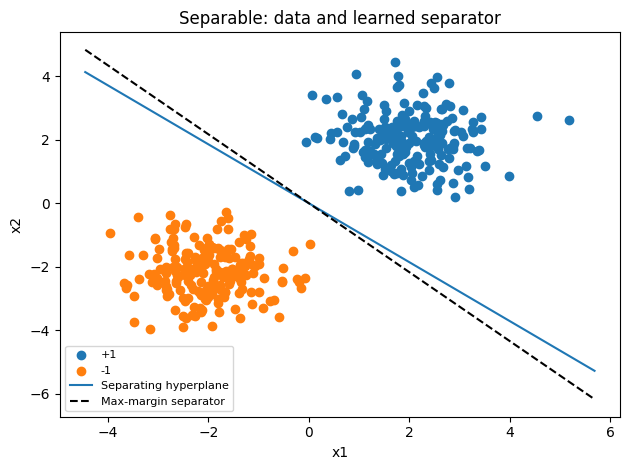

In [12]:
plot_data_with_separator(X_sep, y_sep, w_sep_final, "Separable: data and learned separator", w_max_margin=w_mm)

## Experiment 2: non-separable data

In [13]:
# Run gradient descent and keep all iterates
ws_nonsep, losses_nonsep = train_log_gd(X_nonsep, y_nonsep, steps=1500)

# Extract final parameters
w_nonsep_final = ws_nonsep[-1]

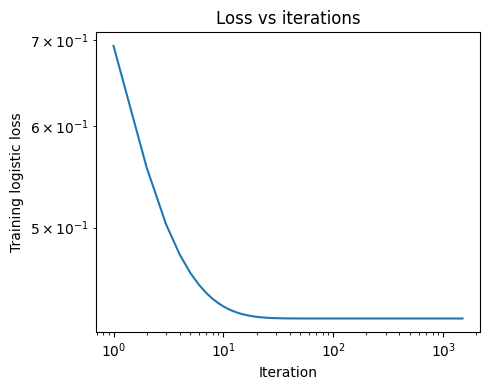

In [14]:
plot_training_loss(losses_nonsep, loglog = True)

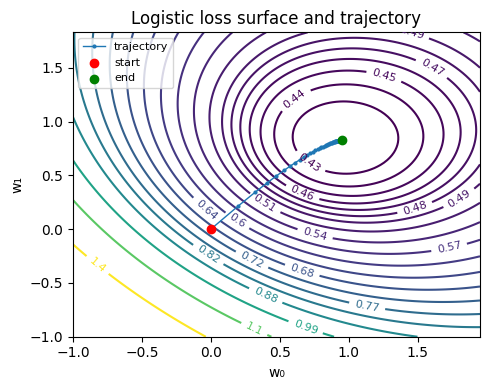

In [15]:
plot_loss_surface(ws_nonsep, X_nonsep, y_nonsep)

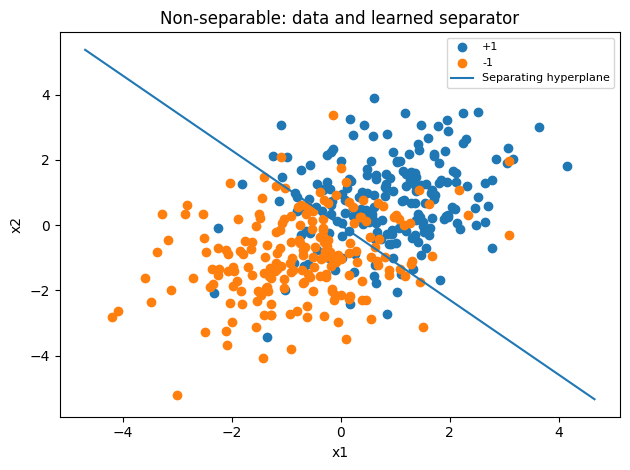

In [16]:
plot_data_with_separator(X_nonsep, y_nonsep, w_nonsep_final, "Non-separable: data and learned separator")

## Experiment 3: $\ell_2$ regularisation on separable data

In [17]:
reg = 0.1
ws_reg, losses_reg = train_log_gd(X_sep, y_sep, steps=1500, reg=reg)
w_reg_final = ws_reg[-1]

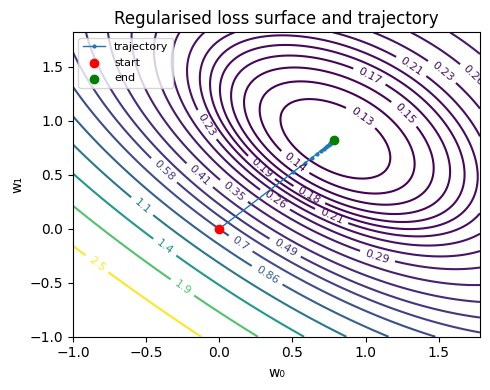

In [18]:
plot_loss_surface(ws_reg, X_sep, y_sep, reg=reg, title="Regularised loss surface and trajectory")

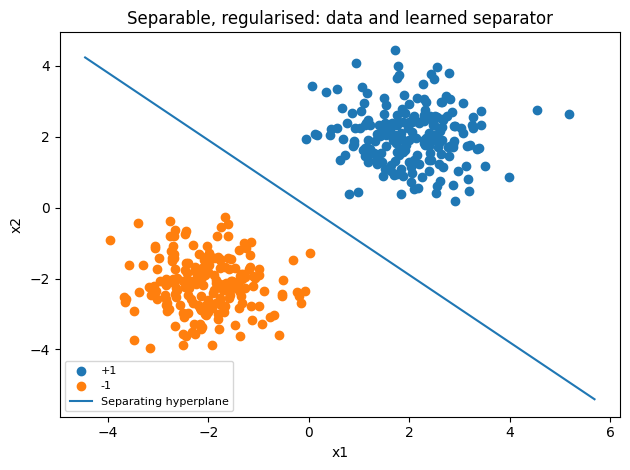

In [19]:
plot_data_with_separator(X_sep, y_sep, w_reg_final, "Separable, regularised: data and learned separator")